# sample

In [29]:
import json
all_data_path = '/home/ywang1/data1/dataset/q2id/Q2ID_data/all_Q2ID_data.jsonl'

# ddt 数据集里，neg 不为空的数据
ddt_query = []
ddt_data = []
with open(all_data_path, 'r') as f:
    for line in f:
        data = json.loads(line)
        # if data['query'] == 'Community Care Centers': # ddl_2015
        #     print(data['source'])
        #     break
        if data['source'] in ['ddt_2015', 'ddt_2016', 'ddt_2017']:
            if data['neg'] != '' and data['neg'] != [''] and data['neg'] != []:
                ddt_query.append(data['query'])
                ddt_data.append(data)

print(len(ddt_query)) 


27


In [24]:
for data in ddt_data:
    print(data['query'])
    # print(data['neg'])


Victoria Stafford - murder trial of Michael Thomas Rafferty
Legislative redistricting in Washington State
Paul and Cathy Lee Martin
Convicted killer Russell Williams is sued
Muskingum County Animal Farm
Fracking's water and tremor problems
Australian Nursing Home Fire
Shafia Canal Lock Murder Trial
The McCleary decision
Zehm Case Upends Spokane County Government
Salmon virus
Community Care Centers
Diagnostic Tests
vaccines drugs vaccine drug
Ebola and Bushmeat
Riots, protests, strikes
Drug protocols for Ebola treatment
Cultural challenges for health workers in controlling transmission
Nano Silver
Telemarketing
Negative SEO
Squeeze Pages
article spinner spinning
Proxy Sales
Are significant changes occurring in ocean productivity
polar ocean global ocean circulation
planning for sea level rise


In [28]:
valid_path = '/home/ywang1/data1/dataset/q2id/Q2ID_data/valid_data_v10.jsonl'
valid_ddt = []
with open(valid_path, 'r') as f:
    for line in f:
        data = json.loads(line)
        if data['query'] in ddt_query:
            valid_ddt.append(data)

print(len(valid_ddt))

for data in valid_ddt:
    print(data['query'])
    # print(data['neg'])
# 原始valid数据集里，没有有neg的ddl数据
# valid_10里的neg是我augment出来的


0


# test on id: 58 in test_data_v10.jsonl for visualization

In [35]:
test_path = '/home/ywang1/data1/dataset/q2id/Q2ID_data/test_data_v10.jsonl'
test_ddt = []
test_data = []
with open(test_path, 'r') as f:
    for line in f:
        data = json.loads(line)
        test_data.append(data)
        if data['query'] in ddt_query:
            test_ddt.append(data)

# test里只有一个ddt有原始neg
# 其他都是augment出来的

In [36]:
for data in test_ddt:
    print(data['sample_id'])
    print(data['query'])
    print(data['intent'])
    print(data['pos'])
    print(data['neg'])

58
Diagnostic Tests
Diagnostic tests for Ebola: How they work, types of tests, speed, and availability.
['Current testing for the Ebola virus requires special biohazard handling and sending test samples long distances to special labs – a process that takes several days. This results in a critical loss of time to diagnose treat and help prevent the spread', 'Current testing for the Ebola virus requires special biohazard handling and sending test samples long distances to special labs – a process that takes several days. This results in a critical loss of time to diagnose, treat and help prevent the spread of the virus. ', 'Most molecular diagnostic technology requires instrumentation and laboratory procedures whereas Diagnostics For All’s device will incorporate the biological mechanical and electronic aspects of a molecular diagnostic into a single disposable device. The device will accept a single finger-stick of blood and provide a clear “yes/no” response in 45 minutes. The partnersh

In [40]:
# select 50 human samplse from prediction_no_neg.json -> google sheet
predictions_no_neg_file = 'predictions_no_neg.json'
test_50_path = '/home/ywang1/data1/dataset/q2id/Q2ID_data/test_data_v10_human_50.jsonl'
test_50_ids = []
with open(test_50_path, 'r') as f:
    for line in f:
        data = json.loads(line)
        test_50_ids.append(data['sample_id'])

print(test_50_ids)
predictions_no_neg_50 = []
predictions_no_neg = []
with open(predictions_no_neg_file, 'r') as f:
    for line in f:
        data = json.loads(line)
        predictions_no_neg.append(data)

    for id in test_50_ids:
        for data in predictions_no_neg:
            if data['sample_id'] == id:
                predictions_no_neg_50.append(data)

print(len(predictions_no_neg_50))

# save predictions_no_neg_50 to csv
import pandas as pd 

df = pd.DataFrame(predictions_no_neg_50)
df.to_csv('predictions_no_neg_50.csv', index=False)


[58, 4, 26, 94, 53, 159, 172, 217, 204, 5149, 1796, 871, 4820, 3874, 1885, 1569, 1022, 2988, 4677, 1352, 4990, 3714, 1252, 1332, 1716, 839, 4139, 2577, 2965, 1575, 3698, 3716, 3466, 3893, 4597, 2769, 3789, 759, 2169, 2779, 2036, 617, 1170, 1051, 482, 4522, 4646, 653, 5122, 4042]
50


In [ ]:
# potential case study ids!!
id_for_test = ['58', '1569', '3893', '2779', '2036', '653']


# 也可以自己编neg docs

# test on attention weights

In [3]:
# write a simple snippte to check attention weights from a small bart model

from transformers import BartForConditionalGeneration, BartTokenizer

model = BartForConditionalGeneration.from_pretrained('facebook/bart-base')
tokenizer = BartTokenizer.from_pretrained('facebook/bart-base')

"""
attentions (tuple(tuple(torch.FloatTensor)), optional, 
returned when output_attentions=True is passed or config.output_attentions=True) — 
Tuple (one element for each generated token) of tuples (one element for each layer of the decoder) of 
torch.FloatTensor of shape (batch_size, num_heads, generated_length, sequence_length).
"""


'\nattentions (tuple(tuple(torch.FloatTensor)), optional, \nreturned when output_attentions=True is passed or config.output_attentions=True) — \nTuple (one element for each generated token) of tuples (one element for each layer of the decoder) of \ntorch.FloatTensor of shape (batch_size, num_heads, generated_length, sequence_length).\n'

In [46]:

# 假设我们有一个query和对应的意图
query = "I want "
intent = "buy_car"

# 使用模型生成意图, 返回意图的attention weights
inputs = tokenizer.encode(query, return_tensors='pt')
outputs = model.generate(inputs, max_length=20, output_attentions=True, return_dict_in_generate=True, output_hidden_states=True, output_scores=True)    


In [47]:

# 结果size
print(outputs.keys())
print(outputs['sequences'])
print(outputs['sequences'].shape)
print(len(outputs['cross_attentions']))
print(tokenizer.decode(outputs['sequences'][0], skip_special_tokens=True))

# 获取意图的attention weights


odict_keys(['sequences', 'sequences_scores', 'scores', 'beam_indices', 'encoder_attentions', 'encoder_hidden_states', 'decoder_attentions', 'cross_attentions', 'decoder_hidden_states'])
tensor([[   2,    0,  100,  236, 1437,    2]])
torch.Size([1, 6])
5
I want 


In [49]:
print(outputs['sequences_scores'])
print(outputs['beam_indices'])
# get index of the highest score 
# -1: Indicates that the token was generated in the current step.


tensor([-0.0008])
tensor([[ 0,  0,  0,  0,  0, -1]])


In [6]:
print(len(outputs['cross_attentions'])) # 9 generated tokens

9


In [7]:
print(len(outputs['cross_attentions'][0])) # 6 layers

6


In [9]:
print(outputs['cross_attentions'][0][0].shape) # 4??? 12 heads, 1 generated token, 8 input tokens

torch.Size([4, 12, 1, 8])


In [45]:
print(outputs['decoder_hidden_states'][-1][-1].shape)

torch.Size([4, 1, 768])


In [54]:
# check token of token_id=1 
import torch
print(tokenizer.encode('currently', add_special_tokens=False))
print(tokenizer.decode(torch.tensor([855])))


[38501]
 currently


In [51]:
# get index of 100 from a tensor tensor([[  2,   0, 100, 236,   2]])
a = torch.where(outputs['sequences'][0] == 236)
print(a[0].tolist()[0])



3


In [58]:
a = ['', '', '', 'Ident', 'ify', ' molecular', ' diagnostic', ' tests', ' currently']
a.index(' currently')

8

# plot attention weights and check focused texts

In [182]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import torch
from transformers import BartForConditionalGeneration, BartTokenizer

# path = '/home/ywang1/workspace/IntentRewriter/visualization/attention_weights.json'\
attention_weights_path = '/home/wangym/workspace/IntentRewriter/visualization/attention_weights.json'
attention_weights = []
with open(attention_weights_path, 'r') as f:
    for line in f:
        attention_weights.append(json.loads(line))

# load text data
tokenizer = BartTokenizer.from_pretrained('facebook/bart-base')
test_data_path = '/home/wangym/workspace/IntentRewriter/visualization/fabricated_217_cleaned.json'
test_data = []
with open(test_data_path, 'r')as f:
    for line in f:
        test_data.append(json.loads(line))


In [183]:
def get_encoded_seq(test_data,  sample_id, type):

    flat_concat = []
    for i in range(len(test_data)):
        if test_data[i]['sample_id'] == sample_id:
            if type == 'neg':
                seq = test_data[i]['neg']
                print('neg seq:', seq)
            else:
                seq = test_data[i]['pos']
                print('pos seq:', seq)
            query = test_data[i]['query']
            break
    query = f"<s>{query}</s>"
    query_encoding = tokenizer.encode(query, 
                                        add_special_tokens = False,
                                        max_length = 1028,
                                        truncation = True)
    query_encoding_length = len(query_encoding)
    flat_concat.extend(query_encoding)

    if type == 'neg':
        doc_encoding = tokenizer.encode(f"{seq[0]}</s>", 
                                         add_special_tokens=False, 
                                         max_length=1028)
        flat_concat.extend(doc_encoding)
    elif type == 'pos':
        for idx in range(len(seq)):
            doc_encoding = tokenizer.encode(f"{seq[idx]}</s>", 
                                                add_special_tokens=False, 
                                                max_length=1024,
                                                truncation=True)
            if len(flat_concat) + len(doc_encoding) > 1024:
                # don't add 0 value
                if 1024 != len(flat_concat):
                    # pos_doc_length.append(1024 - len(flat_concat_pos)) # contains EOS
                    flat_concat += doc_encoding[:1024 - len(flat_concat) - 1] + [doc_encoding[-1]] # must ended with [SEP] ([EOS])
                break
            else:
                flat_concat.extend(doc_encoding)
                # pos_doc_length.append(len(pos_doc_encoding))
    
    return flat_concat, query_encoding_length
    

# 1. plot neg_attention_weights for 21722: with irrelevant document 

In [236]:
# id_pool_58 = [581, 582, 584, 585, 588, 589, 590, 592, 594]
id_pool_217 = [21712, 21722]
# 21712: pos, 21722: pos + neg
sample_id = 21722

# get neg_trunc_length
flat_concat_neg, query_encoding_length = get_encoded_seq(test_data, sample_id, 'neg')
neg_trunc_length = len(flat_concat_neg)
print('neg_trunc_length:', neg_trunc_length)
flat_concat_pos, _ = get_encoded_seq(test_data, sample_id, 'pos')
pos_trunc_length = len(flat_concat_pos)
print('pos_trunc_length:', pos_trunc_length)

print('data size:', len(attention_weights))
print('order:', [d['sample_id'] for d in attention_weights])
# Sample tensor of shape (num_heads, sequence_length)
num_heads = torch.tensor(attention_weights[0]['neg']).shape[0]
sequence_length = torch.tensor(attention_weights[0]['neg']).shape[1]
# print(num_heads, sequence_length)

for i in range(len(attention_weights)):
    if attention_weights[i]['sample_id'] == sample_id:
        print(attention_weights[i]['sample_id'])
        tensor_pos = torch.tensor(attention_weights[i]['pos'])
        tensor_neg = torch.tensor(attention_weights[i]['neg'])
        break


neg seq: ['\n One alternative for cars is a non-CFC-12 refrigerant, but the only chemical combinations discovered so far would require $1,000 or more in modifications to existing air-conditioners. \n All auto manufacturers are developing conversion kits so that systems designed for R-12 can be modified to use R-134a. Some will be relatively simple, others more complicated and expensive. Nevertheless, as R-12 becomes more scarce and costly, auto executives say the conversions will increasingly become the more economical choice. Mr. Oulouhojian said most conversion kits had not yet been developed; their prices are estimated at $200 to $800. He said costs were likely to be lower for newer cars with more modern cooling systems. The cost of completely converting an older car may not make economic sense, he said. But there may be some alternatives, like a partial conversion. "If a customer is willing to accept air that is a few degrees hotter than in the past, the cost may be considerably lo

In [237]:

def plot_attention_weights(tensor, title):
    # Convert tensor to a DataFrame
    df = pd.DataFrame(tensor.T, columns=[f'Head {i+1}' for i in range(num_heads)])

    # Convert the DataFrame to long format
    df_long = df.melt(var_name='Head', value_name='Attention Weight', ignore_index=False)

    # Add a sequence index (x-axis)
    df_long['Position'] = df_long.index

    # Plot the data using Seaborn
    plt.figure(figsize=(10, 6))
    sns.lineplot(data=df_long, x='Position', y='Attention Weight', hue='Head', palette='tab10')
    plt.title(f'{title} Attention Weights for Each Head')
    plt.xlabel('Sequence Position')
    plt.ylabel('Attention Weight')
    plt.legend(title='Heads', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()

    plt.show()

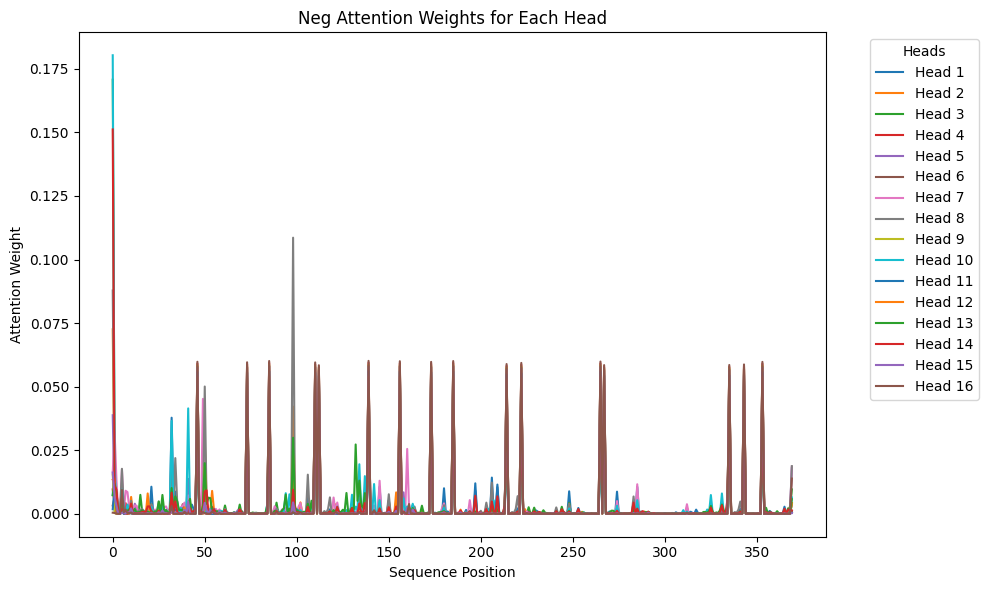

In [238]:
########## neg ################
tensor_neg_trunc = tensor_neg[:, :neg_trunc_length]
plot_attention_weights(tensor_neg_trunc, 'Neg')


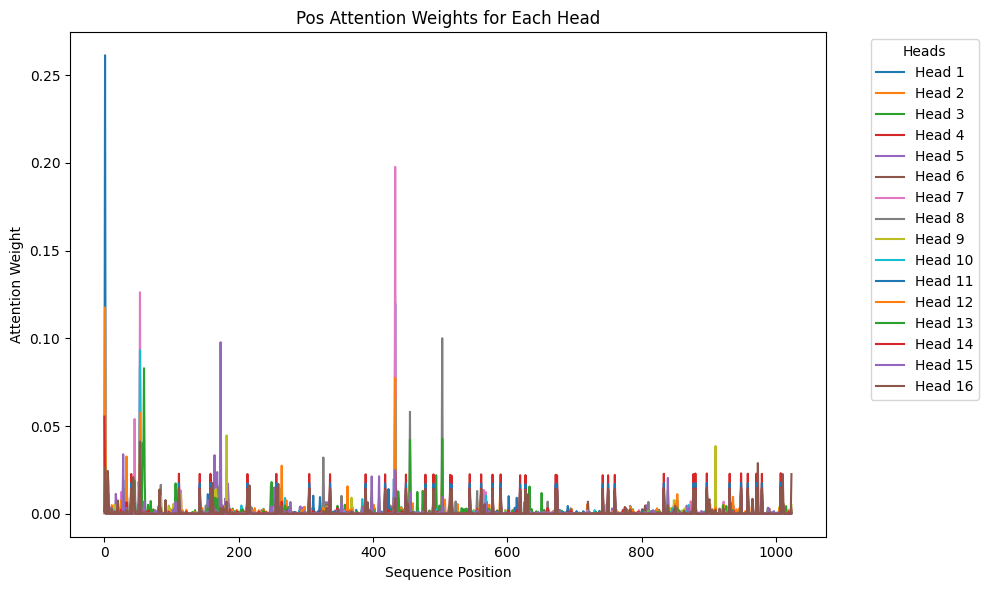

In [239]:
####### pos ###########
tensor_pos = tensor_pos[:, :pos_trunc_length]
plot_attention_weights(tensor_pos, 'Pos')

In [240]:
##### sample id: 582
# <s> Although played a in, was considered to haveopt and (9), and rendered unsuitable for-.
##### sample id: 584
# <s> was by the for the, of ( and well a by, (2), offering the at time (�).
##### sample id: 588
# <s></s>A has been and (). Given, have been (, but to date do not appear have been.</s>
##### sample id: 589
# <s></s>I were, of and have since been a of., have limited due to. In a, respectively (17). </s>
##### sample id: 592
# </s> During the recent, () emerged as powerful for- that can be at. are discussed in the �” section below.</s>
##### sample id: 594
# <s></s>),) ( have been and are ( but the has not as-) have (discussed in �” section below).</s>


In [241]:
###### sample id: 21722
# test on neg doc
focused_ids_neg = []
indices = torch.where(tensor_neg_trunc[1] > 0.005)[0]
# print('indices:',indices)
for i in indices:
    focused_ids_neg.append(flat_concat_neg[i])
# print('focused_ids:', focused_ids_neg)

# get indices of id[0, 2, 1, 4] from focused_ids_neg
cleaned_focused_ids_neg = []
indices_to_remove_neg = []
for i, id in enumerate(focused_ids_neg):
    if id in [0, 2, 1, 4, 50118]:
        indices_to_remove_neg.append(i)
    else:
        cleaned_focused_ids_neg.append(id)
# cleaned indices:
cleaned_indices_neg = [indice.item() for i, indice in enumerate(indices) if i not in indices_to_remove_neg]
# print('indices to remove:', indices_to_remove_neg)
print('cleaned_indices_neg:', cleaned_indices_neg)
print('cleaned_focused_ids_neg:', cleaned_focused_ids_neg)
focused_text_neg = tokenizer.decode(torch.tensor(cleaned_focused_ids_neg))

print('focused_text:', focused_text_neg)

cleaned_indices_neg: [1, 10, 50, 51, 54, 98]
cleaned_focused_ids_neg: [35673, 1677, 4485, 4738, 10012, 4485]
focused_text: Fre cars auto manufacturers conversion auto


# 1.1 plot neg heatmap

In [242]:
####### neg: prepare for heatmap:
### set head
# 21721: head 0,4,5,9,13
head = 13

# 1. get query encoding length
print('query encoding length:', query_encoding_length)
print('query:', tokenizer.decode(torch.tensor(flat_concat_neg[:query_encoding_length])))

# 2. get indices of [0,1,2,4, 50118]
indices_to_remove_neg = []
for i, id in enumerate(flat_concat_neg):
    if id in [0, 1, 2, 4, 50118]:
        indices_to_remove_neg.append(i)
print('indices_to_remove_neg:', indices_to_remove_neg) # [0, 5, 84, 85]
# 3. get attention weights for neg ids ,set weights in  indices_to_remove_neg to 0
for i in indices_to_remove_neg:
    tensor_neg[head][i] = 0 # head1, position i
neg_attention_weights = tensor_neg[head][query_encoding_length:neg_trunc_length]
print('legnth of neg_attention_weights:', len(neg_attention_weights))
print('range of neg_attention_weights:', neg_attention_weights.max(), neg_attention_weights.min())
# 4. split neg_ids
neg_ids = flat_concat_neg[query_encoding_length:]
neg_tokens = tokenizer.batch_decode(neg_ids, skip_special_tokens=True)
neg_tokens[-1] = ''
print('length of neg_ids:', len(neg_ids))
print('length of neg_tokens:', len(neg_tokens))

# plot heatmap
# x axis: indices of neg_ids
# color: attention weights
# x tick: neg_tokens

query encoding length: 6
query: <s>Freon-12</s>
indices_to_remove_neg: [0, 5, 6, 46, 48, 73, 85, 110, 112, 139, 156, 173, 185, 214, 222, 224, 265, 267, 335, 343, 353, 368, 369]
legnth of neg_attention_weights: 364
range of neg_attention_weights: tensor(0.0095) tensor(0.)
length of neg_ids: 364
length of neg_tokens: 364


size of tokens_reshaped: (8, 20)


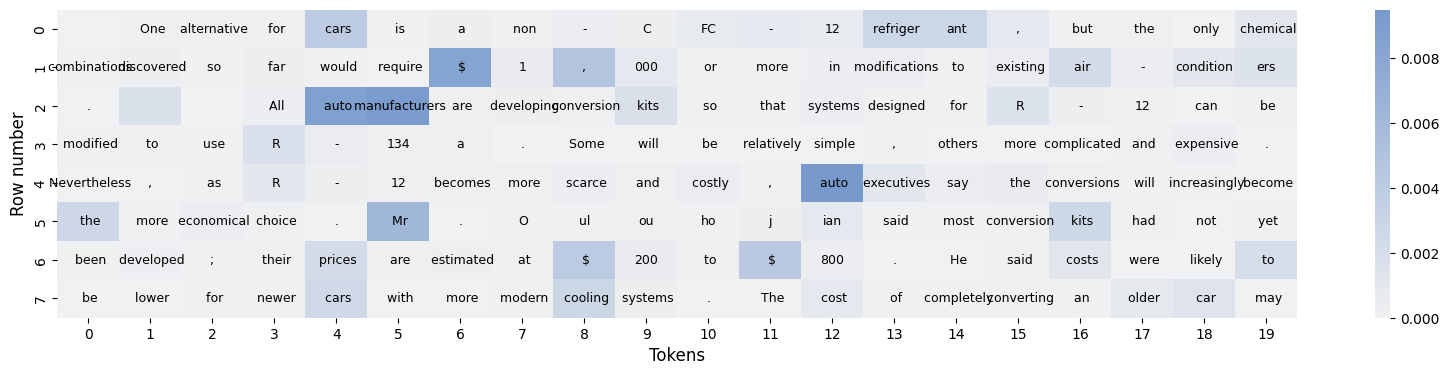

In [243]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

############## reshape for better visualization
# 1. remove the last </s> in the last step
# set row number
row_num = 8
trunc_length = 160
# sum neg_attention_weights over dim 0
# neg_attention_weights = tensor_neg.sum(dim=0)
# totoal_num = 160
# 2. optional: expand the existing neg_attention_weights and neg_tokens to size 120 with zeros
neg_attention_weights = neg_attention_weights[:trunc_length]
neg_tokens = neg_tokens[:trunc_length]
# neg_attention_weights = torch.nn.functional.pad(neg_attention_weights, (0, totoal_num - neg_attention_weights.size(0)))
# neg_tokens.extend(['']*(totoal_num - len(neg_tokens)))

# Convert attention weights to 2D (1xN) array for the heatmap
attention_weights_reshaped = np.array([neg_attention_weights]).reshape(row_num, -1)
tokens_reshaped = np.array(neg_tokens).reshape(row_num, -1)
print('size of tokens_reshaped:', tokens_reshaped.shape)

plt.figure(figsize=(20, 4))
# Create the heatmap
# palette = sns.cubehelix_palette(gamma=.5, as_cmap=True)
palette = sns.light_palette("#79C", as_cmap=True) # #79C
ax = sns.heatmap(attention_weights_reshaped, annot=False, cmap=palette)

# Add text annotations manually
for i in range(tokens_reshaped.shape[0]):
    for j in range(tokens_reshaped.shape[1]):
        ax.text(j + 0.5, i + 0.5, tokens_reshaped[i, j], 
                ha='center', va='center', fontsize=9,
                color='black' if attention_weights_reshaped[i, j] < 0.5 else 'white')

# Customize labels
plt.xlabel('Tokens', fontsize=12)
plt.ylabel('Row number', fontsize=12)

# Show the plot
plt.savefig('neg_21722.png', dpi=300, bbox_inches='tight')
plt.show()


# 1.2 plot pos heatmap

In [244]:
##### indices for pos doc ####
focused_ids_pos = []
indices = torch.where(tensor_pos[1] > 0.005)[0]
# print('indices:',indices)
for i in indices:
    focused_ids_pos.append(flat_concat_pos[i])
# print('focused_ids:', focused_ids_pos)

# get indices of id[0, 2, 1, 4] from focused_ids_pos
cleaned_focused_ids_pos = []
indices_to_remove_pos = []
for i, id in enumerate(focused_ids_pos):
    if id in [0, 2, 1, 4, 50118]:
        indices_to_remove_pos.append(i)
    else:
        cleaned_focused_ids_pos.append(id)
# cleaned indices:
cleaned_indices_pos = [indice.item() for i, indice in enumerate(indices) if i not in indices_to_remove_pos]
# print('indices to remove:', indices_to_remove_neg)
print('cleaned_indices_pos:', len(cleaned_indices_pos), cleaned_indices_pos)
print('cleaned_focused_ids_pos:',len(cleaned_focused_ids_pos), cleaned_focused_ids_pos)
focused_text_pos = tokenizer.decode(torch.tensor(cleaned_focused_ids_pos))

print('focused_text:', focused_text_pos)

cleaned_indices_pos: 24 [1, 2, 20, 28, 33, 45, 53, 54, 173, 264, 353, 433, 434, 455, 459, 503, 507, 526, 555, 566, 569, 573, 589, 719]
cleaned_focused_ids_pos: 24 [35673, 261, 34011, 2623, 23084, 3470, 5547, 261, 24230, 23084, 1677, 5547, 261, 4485, 10012, 4485, 30869, 10012, 1677, 18841, 512, 776, 10012, 30869]
focused_text: Freon ozone developing HC Old Freon richer HC cars Freon auto conversion auto conversions conversion cars converting car economic conversion conversions


In [277]:
####### pos: prepare for heatmap:
### set head
# 21721: head 1, 3, 4 pric,5 price , 14 no price
head = 15

# 1. get query encoding length
print('query encoding length:', query_encoding_length)
print('query:', tokenizer.decode(torch.tensor(flat_concat_pos[:query_encoding_length])))

# 2. get indices of [0,1,2,4,50118]
indices_to_remove_pos = []
for i, id in enumerate(flat_concat_pos):
    if id in [0, 1, 2, 4, 50118]:
        indices_to_remove_pos.append(i)
print('indices_to_remove_pos:', indices_to_remove_pos) # [0, 5, 84, 85]
# 3. get attention weights for neg ids ,set weights in  indices_to_remove_neg to 0
for i in indices_to_remove_pos:
    tensor_pos[head][i] = 0 # head1, position i
pos_attention_weights = tensor_pos[head][query_encoding_length:pos_trunc_length]
print('legnth of pos_attention_weights:', len(pos_attention_weights))
print('range of pos_attention_weights:', pos_attention_weights.max(), pos_attention_weights.min())
# 4. split pos_ids
pos_ids = flat_concat_pos[query_encoding_length:]
pos_tokens = tokenizer.batch_decode(pos_ids, skip_special_tokens=True)
pos_tokens[-1] = ''
print('length of pos_ids:', len(pos_ids))
print('length of pos_tokens:', len(pos_tokens))

query encoding length: 6
query: <s>Freon-12</s>
indices_to_remove_pos: [0, 5, 6, 40, 42, 43, 44, 81, 82, 83, 111, 142, 158, 160, 161, 162, 213, 215, 216, 217, 256, 258, 259, 260, 305, 336, 347, 348, 349, 389, 391, 392, 393, 418, 449, 451, 452, 453, 478, 490, 515, 517, 544, 561, 578, 590, 619, 627, 629, 630, 631, 672, 674, 742, 750, 760, 775, 776, 777, 833, 877, 880, 897, 899, 900, 901, 931, 948, 958, 971, 979, 1007, 1009, 1010, 1011, 1023]
legnth of pos_attention_weights: 1018
range of pos_attention_weights: tensor(0.0412) tensor(0.)
length of pos_ids: 1018
length of pos_tokens: 1018


size of tokens_reshaped: (5, 20)


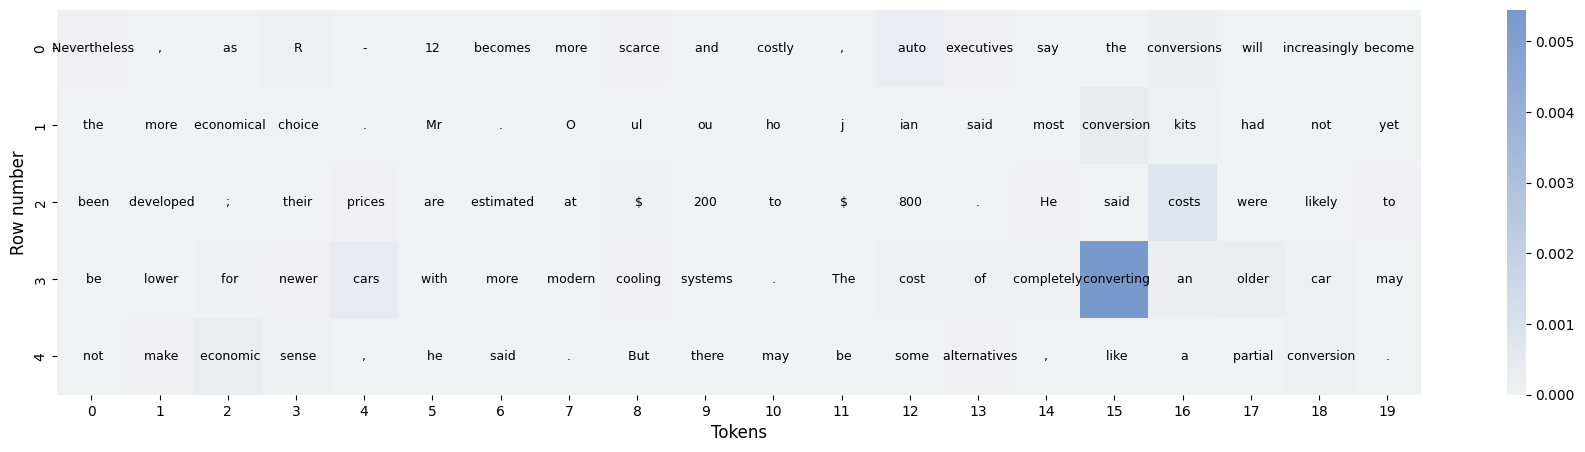

In [278]:
############## reshape for better visualization
# 1. remove the last </s> in the last step
# set row number
row_num = 5
trunc_length = 1000

# 2. optional: expand the existing neg_attention_weights and neg_tokens to size 120 with zeros
# pos_attention_weights = pos_attention_weights[:trunc_length]
# pos_tokens = pos_tokens[:trunc_length]
########
pos_tokens = pos_tokens[485: 585]
pos_attention_weights = pos_attention_weights[485: 585]

# Convert attention weights to 2D (1xN) array for the heatmap
attention_weights_reshaped = np.array([pos_attention_weights]).reshape(row_num, -1)
tokens_reshaped = np.array(pos_tokens).reshape(row_num, -1)
print('size of tokens_reshaped:', tokens_reshaped.shape)

plt.figure(figsize=(22, 5))
# Create the heatmap
# palette = sns.cubehelix_palette(gamma=.5, as_cmap=True)
palette = sns.light_palette("#79C", as_cmap=True) # #79C
ax = sns.heatmap(attention_weights_reshaped, annot=False, cmap=palette)

# Add text annotations manually
for i in range(tokens_reshaped.shape[0]):
    for j in range(tokens_reshaped.shape[1]):
        ax.text(j + 0.5, i + 0.5, tokens_reshaped[i, j], 
                ha='center', va='center', fontsize=9,
                color='black' if attention_weights_reshaped[i, j] < 0.5 else 'white')

# Customize labels
plt.xlabel('Tokens', fontsize=12)
plt.ylabel('Row number', fontsize=12)

# Show the plot
plt.savefig(f'./plot/pos_21722_head{head}.png', dpi=300, bbox_inches='tight')
plt.show()

# plot pos attention weights on 21712: without irrelevant document

In [279]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import torch
from transformers import BartForConditionalGeneration, BartTokenizer

# path = '/home/ywang1/workspace/IntentRewriter/visualization/attention_weights.json'\
attention_weights_path = '/home/wangym/workspace/IntentRewriter/visualization/attention_weights.json'
attention_weights = []
with open(attention_weights_path, 'r') as f:
    for line in f:
        attention_weights.append(json.loads(line))

# load text data
tokenizer = BartTokenizer.from_pretrained('facebook/bart-base')
test_data_path = '/home/wangym/workspace/IntentRewriter/visualization/fabricated_217_cleaned.json'
test_data = []
with open(test_data_path, 'r')as f:
    for line in f:
        test_data.append(json.loads(line))

/home/wangym/data1/miniconda3/envs/intent/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [280]:
# id_pool_58 = [581, 582, 584, 585, 588, 589, 590, 592, 594]
id_pool_217 = [21712, 21722]
# 21712: pos, 21722: pos + neg
sample_id = 21712

# get neg_trunc_length
flat_concat_neg, query_encoding_length = get_encoded_seq(test_data, sample_id, 'neg')
neg_trunc_length = len(flat_concat_neg)
print('neg_trunc_length:', neg_trunc_length)
flat_concat_pos, _ = get_encoded_seq(test_data, sample_id, 'pos')
pos_trunc_length = len(flat_concat_pos)
print('pos_trunc_length:', pos_trunc_length)

print('data size:', len(attention_weights))
print('order:', [d['sample_id'] for d in attention_weights])
# Sample tensor of shape (num_heads, sequence_length)
num_heads = torch.tensor(attention_weights[0]['neg']).shape[0]
sequence_length = torch.tensor(attention_weights[0]['neg']).shape[1]
# print(num_heads, sequence_length)

for i in range(len(attention_weights)):
    if attention_weights[i]['sample_id'] == sample_id:
        print(attention_weights[i]['sample_id'])
        tensor_pos = torch.tensor(attention_weights[i]['pos'])
        tensor_neg = torch.tensor(attention_weights[i]['neg'])
        break

Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.


neg seq: ['']
neg_trunc_length: 7
pos seq: ['\n By contrast, the Montreal Protocol, which governs the phaseout of ozone-depleting chemicals, allows developing countries to continue using HCFC-22 through 2040. \n', '\n Old air-conditioners, still containing Freon, are being dumped illegally in Park Slope section of Brooklyn, possibly by work crews renovating buildings; photo (M) \n', '\n MCF is among a group of ozone-depleting substances selected to be phased out under provisions of various international agreements and national regulations. Other such substances include chlorofluorocarbons, halons, carbon tetrachloride and hydrochlorofluorocarbons. The international Montreal Protocol set a deadline of 2005 for the worldwide phase-out. \n', "\n Under an environmental treaty signed in 1987 in Montreal, richer countries have drastically curbed their use of substances that deplete the ozone shield, especially chlorofluorocarbons, or CFC's, used in air-conditioners and refrigerators. \n", '\

In [281]:
##### indices for pos doc ####
focused_ids_pos = []
indices = torch.where(tensor_pos[1] > 0.005)[0]
# print('indices:',indices)
for i in indices:
    focused_ids_pos.append(flat_concat_pos[i])
# print('focused_ids:', focused_ids_pos)

# get indices of id[0, 2, 1, 4] from focused_ids_pos
cleaned_focused_ids_pos = []
indices_to_remove_pos = []
for i, id in enumerate(focused_ids_pos):
    if id in [0, 2, 1, 4, 50118]:
        indices_to_remove_pos.append(i)
    else:
        cleaned_focused_ids_pos.append(id)
# cleaned indices:
cleaned_indices_pos = [indice.item() for i, indice in enumerate(indices) if i not in indices_to_remove_pos]
# print('indices to remove:', indices_to_remove_neg)
print('cleaned_indices_pos:', len(cleaned_indices_pos), cleaned_indices_pos)
print('cleaned_focused_ids_pos:',len(cleaned_focused_ids_pos), cleaned_focused_ids_pos)
focused_text_pos = tokenizer.decode(torch.tensor(cleaned_focused_ids_pos))

print('focused_text:', focused_text_pos)

cleaned_indices_pos: 16 [59, 353, 455, 503, 513, 547, 552, 553, 554, 555, 569, 573, 660, 695, 721, 723]
cleaned_focused_ids_pos: 16 [5176, 1677, 4485, 4485, 33366, 1042, 795, 13, 13964, 1677, 512, 776, 512, 512, 5, 1393]
focused_text:  illegally cars auto auto economical costs lower for newer cars car economic car car the driver


In [290]:
####### pos: prepare for heatmap:
### set head
# 21721: head 1, 3, 4 pric,5 price , 14 no price
head = 15

# 1. get query encoding length
print('query encoding length:', query_encoding_length)
print('query:', tokenizer.decode(torch.tensor(flat_concat_pos[:query_encoding_length])))

# 2. get indices of [0,1,2,4,50118]
indices_to_remove_pos = []
for i, id in enumerate(flat_concat_pos):
    if id in [0, 1, 2, 4, 50118]:
        indices_to_remove_pos.append(i)
print('indices_to_remove_pos:', indices_to_remove_pos) # [0, 5, 84, 85]
# 3. get attention weights for neg ids ,set weights in  indices_to_remove_neg to 0
for i in indices_to_remove_pos:
    tensor_pos[head][i] = 0 # head1, position i
pos_attention_weights = tensor_pos[head][query_encoding_length:pos_trunc_length]
print('legnth of pos_attention_weights:', len(pos_attention_weights))
print('range of pos_attention_weights:', pos_attention_weights.max(), pos_attention_weights.min())
# 4. split pos_ids
pos_ids = flat_concat_pos[query_encoding_length:]
pos_tokens = tokenizer.batch_decode(pos_ids, skip_special_tokens=True)
pos_tokens[-1] = ''
print('length of pos_ids:', len(pos_ids))
print('length of pos_tokens:', len(pos_tokens))

query encoding length: 6
query: <s>Freon-12</s>
indices_to_remove_pos: [0, 5, 6, 40, 42, 43, 44, 81, 82, 83, 111, 142, 158, 160, 161, 162, 213, 215, 216, 217, 256, 258, 259, 260, 305, 336, 347, 348, 349, 389, 391, 392, 393, 418, 449, 451, 452, 453, 478, 490, 515, 517, 544, 561, 578, 590, 619, 627, 629, 630, 631, 672, 674, 742, 750, 760, 775, 776, 777, 833, 877, 880, 897, 899, 900, 901, 931, 948, 958, 971, 979, 1007, 1009, 1010, 1011, 1023]
legnth of pos_attention_weights: 1018
range of pos_attention_weights: tensor(0.0070) tensor(0.)
length of pos_ids: 1018
length of pos_tokens: 1018


size of tokens_reshaped: (5, 20)


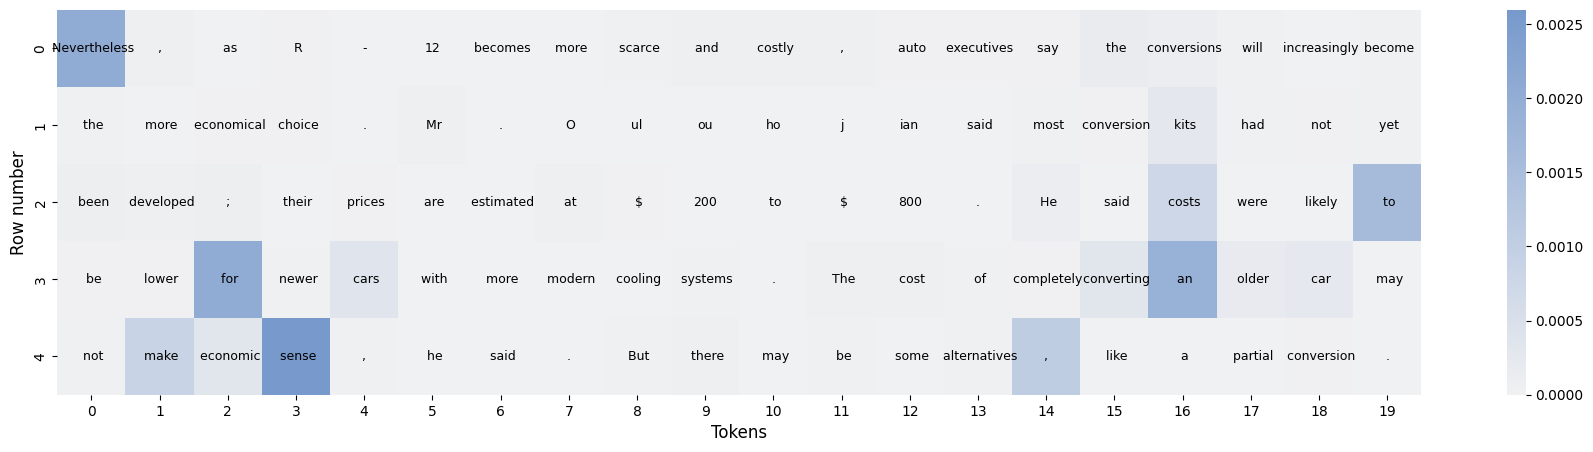

In [291]:
############## reshape for better visualization
# 1. remove the last </s> in the last step
# set row number
row_num = 5
trunc_length = 1000

# 2. optional: expand the existing neg_attention_weights and neg_tokens to size 120 with zeros
# pos_attention_weights = pos_attention_weights[:trunc_length]
# pos_tokens = pos_tokens[:trunc_length]
########
# [485: 585]
pos_tokens = pos_tokens[485: 585]
pos_attention_weights = pos_attention_weights[485: 585]

# Convert attention weights to 2D (1xN) array for the heatmap
attention_weights_reshaped = np.array([pos_attention_weights]).reshape(row_num, -1)
tokens_reshaped = np.array(pos_tokens).reshape(row_num, -1)
print('size of tokens_reshaped:', tokens_reshaped.shape)

plt.figure(figsize=(22, 5))
# Create the heatmap
# palette = sns.cubehelix_palette(gamma=.5, as_cmap=True)
palette = sns.light_palette("#79C", as_cmap=True) # #79C
ax = sns.heatmap(attention_weights_reshaped, annot=False, cmap=palette)

# Add text annotations manually
for i in range(tokens_reshaped.shape[0]):
    for j in range(tokens_reshaped.shape[1]):
        ax.text(j + 0.5, i + 0.5, tokens_reshaped[i, j], 
                ha='center', va='center', fontsize=9,
                color='black' if attention_weights_reshaped[i, j] < 0.5 else 'white')

# Customize labels
plt.xlabel('Tokens', fontsize=12)
plt.ylabel('Row number', fontsize=12)

# Show the plot
plt.savefig(f'./plot/pos_21712_head{head}.png', dpi=300, bbox_inches='tight')
plt.show()

In [224]:
sns.cubehelix_palette(gamma=.5)

[[0.9677582443832915, 0.9051255132712561, 0.8921317049638422],
 [0.9366516168521423, 0.7987541751981306, 0.8203477812174477],
 [0.883435589853139, 0.6844441392020983, 0.7747394075250862],
 [0.7926086676355076, 0.5722187349695307, 0.7399829210830132],
 [0.6457727972419955, 0.4569922469969748, 0.684922242569941],
 [0.4347492929500456, 0.32880347098616963, 0.5601082371116484]]

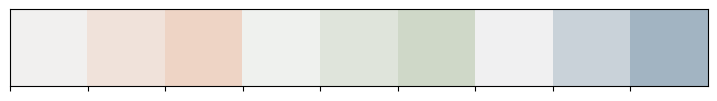

In [237]:
# Define the four main colors
colors = ["#EDC6B1", "#B7B7B7", "#BFCCB5", "#7C96AB"]

# Create palettes for each color with decreasing brightness
palette1 = sns.light_palette(colors[0], n_colors=4, reverse=False)
# palette2 = sns.light_palette(colors[1], n_colors=4, reverse=False)
palette3 = sns.light_palette(colors[2], n_colors=4, reverse=False)
palette4 = sns.light_palette(colors[3], n_colors=4, reverse=False)

# Combine all the palettes into one
custom_palette = palette1[:3] + palette3[:3] + palette4[:3]

# Plot the palette
sns.palplot(custom_palette)

plt.show()

AttributeError: 'Text' object has no property 'highlight_weights'

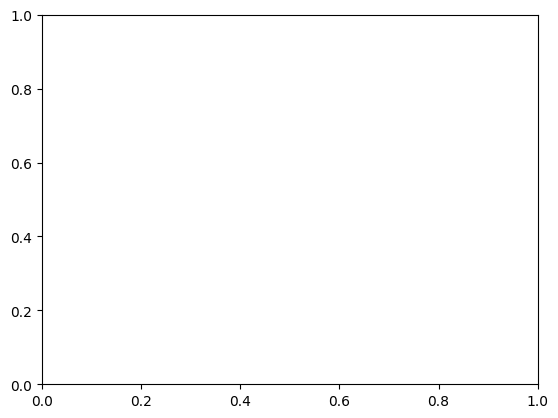

In [1]:
import matplotlib.pyplot as plt
from highlight_text import fig_text

text = "This is a sample sentence where certain words are highlighted."
plt.figure(figsize=(10, 6))
fig_text(0.1, 0.5, text, highlight_weights={'sample': 'bold', 'highlighted': 'italic'}, color='black', fontsize=14)
plt.show()

In [22]:
import spacy
from spacy import displacy

# Load a blank spacy model for demonstration
nlp = spacy.blank('en')

# Sample text and attention scores (mock values for illustration)
text = "This is an example sentence with attention scores."
attention_scores = [0.1, 0.2, 0.7, 0.9, 0.5, 0.8, 0.3, 0.6, 0.1]

# Create a spaCy doc object
doc = nlp(text)

# Define colors based on attention scores
# Higher attention score -> more intense color
def score_to_color(score):
    if score > 0.8:
        return '#FF5733'  # High attention: Red
    elif score > 0.6:
        return '#FFC300'  # Medium-high attention: Yellow
    elif score > 0.4:
        return '#DAF7A6'  # Medium-low attention: Light green
    else:
        return '#33FF57'  # Low attention: Green

# Convert attention scores to spans
spans = []
start = 0
for i, token in enumerate(doc):
    end = start + len(token) # character level start,end index
    # print(start, end)
    color = score_to_color(attention_scores[i])
    spans.append({
        "start": start,
        "end": end,
        "label": f"ATTENTION_{i}",
        "color": color
    })
    start = end + 1  # Add 1 for the space after the token

# Visualize using displaCy with the attention-based colors
options = {
    "colors": {},
    "ents": [f"ATTENTION_{i}" for i in range(len(spans))],
    "spans_key": None,
    "display_label": False  # This option hides the labels
}
for span in spans:
    options["colors"][span["label"]] = span["color"]
    
print(options)
ents = []
for span in spans:
    char_span = doc.char_span(span["start"], span["end"], label=span["label"])
    if char_span is not None:
        ents.append(char_span)

# Assign the entities to the document
doc.ents = ents

# Render the highlighted text
html = displacy.render(doc, style="ent", options=options)
display(HTML(html))


{'colors': {'ATTENTION_0': '#33FF57', 'ATTENTION_1': '#33FF57', 'ATTENTION_2': '#FFC300', 'ATTENTION_3': '#FF5733', 'ATTENTION_4': '#DAF7A6', 'ATTENTION_5': '#FFC300', 'ATTENTION_6': '#33FF57', 'ATTENTION_7': '#DAF7A6', 'ATTENTION_8': '#33FF57'}, 'ents': ['ATTENTION_0', 'ATTENTION_1', 'ATTENTION_2', 'ATTENTION_3', 'ATTENTION_4', 'ATTENTION_5', 'ATTENTION_6', 'ATTENTION_7', 'ATTENTION_8'], 'spans_key': None, 'display_label': False}


<IPython.core.display.HTML object>